# Plotting and appearance

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ContextLab/htfa/blob/main/docs/tutorials/11_plotting_and_appearance.ipynb)

This notebook goes through the options that change how htfa figures look: the BrainNet Viewer-style 3D network renderer (`htfa.plot_network`, `htfa.brainnet`), the time-course ribbons (`htfa.plot_timecourse`), and the matplotlib / nilearn plots on `HTFAResults`.

**Data used in each section.**

- Sections 1 to 10 (3D network renderer, BrainNet option file, side-by-side panels): a real HTFA fit on six adults from nilearn's `development_fmri` dataset (Pixar "Partly Cloudy" viewing, 168 volumes, TR = 2 s), described in section 1.
- Section 11 (time courses): synthetic subject-by-time curves made with a seeded random generator, except the last pair of panels, which uses real sliding-window connectivity from the same fit.
- Section 12 (`plot_nodes`, `plot_connectivity` on 3D data): the same real fit.
- Section 13 (`plot_nodes`, `plot_connectivity`, `plot_reconstruction` on 2D data): synthetic images from `htfa.make_tfa_data`.
- Section 14 (nodes drawn inside the brain, `snap`): the same real fit.
- Section 15 (animation options): the same real fit.

The first run of the notebook downloads the dataset (nilearn) and the brain meshes (NITRC, see `htfa.brainnet.fetch_mesh`) and, by default, a saved copy of the HTFA fit (section 1); later runs reuse the downloaded files.

In [1]:
# Install htfa if it is missing (for example on Colab); other packages
# install themselves the first time they are needed.
try:
    import htfa  # noqa: F401
except ImportError:
    %pip install -q "htfa @ git+https://github.com/ContextLab/htfa"

In [2]:
import hashlib
import json
import os
import tempfile
import time
import urllib.request
import warnings
from pathlib import Path

import numpy as np
import scipy.io
from IPython.display import display
from sklearn.exceptions import ConvergenceWarning

import htfa
from htfa import brainnet, timecourse

plt = htfa.require("matplotlib.pyplot")
Image = htfa.require("PIL.Image")
ImageChops = htfa.require("PIL.ImageChops")
warnings.filterwarnings("ignore", message="A worker stopped")

CACHE = Path.home() / ".cache" / "htfa" / "tutorials" / "11"
CACHE.mkdir(parents=True, exist_ok=True)

## 1. Data and fit

The first six adults are downloaded and preprocessed by `htfa.datasets.fetch_development_fmri` (MNI152 brain mask, voxels outside the subject's brain dropped, linear detrend plus confound regression per run), and HTFA is fitted with `K=30`, `init='ncorr'` and the subsampling described in `docs/performance.rst` (`max_voxels=5000`, `max_trs=168`). The fit is deliberately short (6 global iterations); it is meant to give realistic inputs for the plots, not a converged template.

By default (`REFIT = False`) the next cell downloads a saved copy of this fit from the `tutorial-data-v1` data release of the htfa repository, checks its SHA-256 and loads it with `np.load(..., allow_pickle=False)`; the printed lines give its settings, the htfa commit that made it and the machine. The saved fit may be regenerated when htfa's fitting code changes. `REFIT = True` fits HTFA from scratch instead, with one parallel job per CPU (`n_jobs=os.cpu_count()`); that result is not cached.

In [3]:
# Fit from scratch (True), or download the saved fit made with these settings
# (False, the default; 0.2 MB). The saved file records the htfa commit that
# made it; it may be regenerated when htfa's fitting code changes.
REFIT = False

FIT_URL = (
    "https://github.com/ContextLab/htfa/releases/download/tutorial-data-v1/"
    "htfa_development_fmri_6adults_K30.npz"
)
FIT_SHA256 = "48d0cdda811a515fad809b2b667f29d470cf5c2c19c53a9c7bc29495ee4ba829"


def download_saved_fit():
    """Download the saved fit (once), check its SHA-256 and return its path."""
    path = CACHE / FIT_URL.rsplit("/", 1)[1]
    if not path.exists():
        tmp = path.with_suffix(".part")
        try:
            urllib.request.urlretrieve(FIT_URL, tmp)
        except OSError as err:
            raise RuntimeError(
                f"could not download the saved fit from {FIT_URL} ({err}); "
                "set REFIT = True to fit HTFA from scratch"
            ) from err
        tmp.rename(path)
    digest = hashlib.sha256(path.read_bytes()).hexdigest()
    if digest != FIT_SHA256:
        path.unlink()
        raise RuntimeError(
            f"the downloaded fit has SHA-256 {digest}, expected {FIT_SHA256}; "
            "it was deleted. Run the cell again, or set REFIT = True to fit HTFA "
            "from scratch"
        )
    return path


def print_provenance(fit):
    print("saved fit:", FIT_URL)
    print(f"SHA-256 {FIT_SHA256} (checked)")
    print("settings:", fit["settings"])
    print(
        f"fitted with htfa {fit['htfa_version']} at commit {fit['htfa_commit']} "
        f"on {fit['machine']}"
    )


settings = dict(
    K=30,
    max_global_iter=6,
    max_local_iter=5,
    max_voxels=5000,
    max_trs=168,
    init="ncorr",
    random_state=0,
)
ds = htfa.datasets.fetch_development_fmri(n_subjects=6)
Xs, Rs = ds.data, ds.coords
if REFIT:
    t0 = time.perf_counter()
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", ConvergenceWarning)
        res = htfa.fit(Xs, coords=Rs, **settings, n_jobs=os.cpu_count())
    fit_seconds = time.perf_counter() - t0
else:
    with np.load(download_saved_fit(), allow_pickle=False) as z:
        fit = {k: z[k] for k in z.files}
    saved = json.loads(str(fit["settings"]))
    assert {k: saved[k] for k in settings} == settings, saved
    assert list(fit["subject_ids"]) == ds.subject_ids, fit["subject_ids"]
    print_provenance(fit)
    model = htfa.HTFA(**settings)  # filled with the saved estimates
    model.centers_ = list(fit["centers"])
    model.widths_ = list(fit["widths"])
    model.weights_ = list(fit["weights"])
    model.global_centers_ = fit["global_centers"]
    model.global_widths_ = fit["global_widths"]
    model.n_iter_ = int(fit["n_iter"])
    model.converged_ = bool(fit["converged"])
    res = htfa.HTFAResults(model, htfa.load(Xs, coords=Rs))
    fit_seconds = float(fit["fit_seconds"])
print(f"fit time: {fit_seconds:.0f} s")
print(
    "subjects:",
    len(res.subjects),
    " voxels per subject:",
    [s.data.shape[0] for s in res.subjects],
)
print(
    "time points:",
    res.subjects[0].data.shape[1],
    " factors:",
    res.global_centers.shape[0],
)
print(
    "template widths, min / max:",
    np.round([res.global_widths.min(), res.global_widths.max()]),
)

saved fit: https://github.com/ContextLab/htfa/releases/download/tutorial-data-v1/htfa_development_fmri_6adults_K30.npz
SHA-256 48d0cdda811a515fad809b2b667f29d470cf5c2c19c53a9c7bc29495ee4ba829 (checked)
settings: {"K": 30, "init": "ncorr", "max_global_iter": 6, "max_local_iter": 5, "max_trs": 168, "max_voxels": 5000, "n_jobs": 12, "random_state": 0}
fitted with htfa 0.1.0 at commit f6691a88189b62e65df11ef8708c1ec7c3ac0f63 on Darwin arm64, 12 CPUs
fit time: 43 s
subjects: 6  voxels per subject: [25079, 23726, 26739, 27257, 27038, 27918]
time points: 168  factors: 30
template widths, min / max: [ 473. 2379.]


## 2. A first network

`htfa.plot_network(res, connectivity, subject=0)` draws the factors of subject 0 as spheres (by default at their in-brain positions, see section 14) inside a translucent brain surface and the edges of `connectivity` whose absolute value exceeds `threshold`. Node size comes from the fitted factor widths unless `sizes` is given. Edges are red for positive and blue for negative weights. The call returns a `PIL.Image.Image`.

The connectivity used from here on is subject 0's static factor-weight correlation (`res.connectivity(0)`) with the diagonal set to zero. The printed values give the scale the thresholds below act on. The default threshold is 0.25.

edges (upper triangle): 435
percentiles 50/75/90/99 of |r|: [0.2  0.32 0.52 0.71]
edges with |r| > 0.5: 49 of which negative: 14


Image (900, 560) 1.8 s


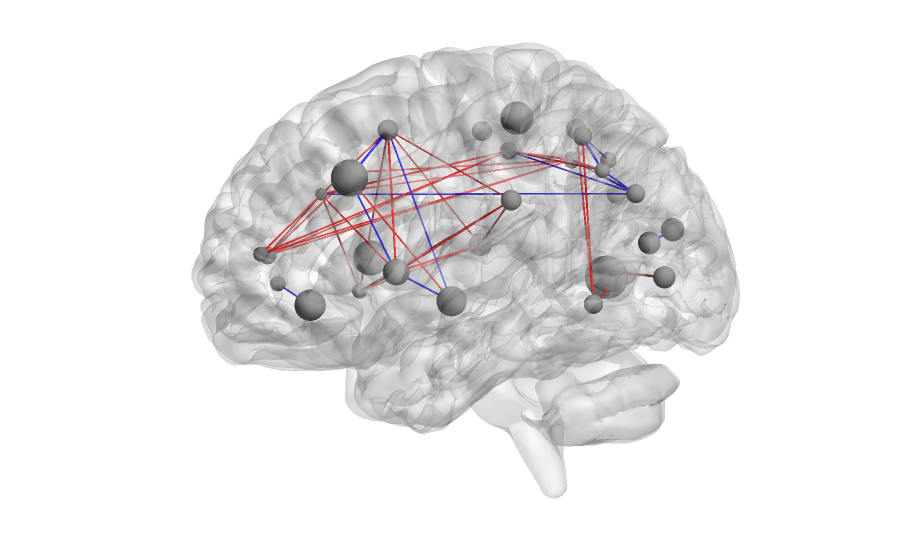

In [4]:
C0 = res.connectivity(0)
np.fill_diagonal(C0, 0)
iu = np.triu_indices(30, 1)
a = np.abs(C0[iu])
print("edges (upper triangle):", a.size)
print(
    "percentiles 50/75/90/99 of |r|:", np.round(np.percentile(a, [50, 75, 90, 99]), 2)
)
print(
    "edges with |r| > 0.5:",
    int((a > 0.5).sum()),
    "of which negative:",
    int((C0[iu] < -0.5).sum()),
)


def show(img, width=None):
    # Downscale for the docs. The image keeps its pixels when width is None.
    if width is not None:
        img = img.resize((width, round(img.height * width / img.width)), Image.LANCZOS)
    display(img)


t0 = time.perf_counter()
img = htfa.plot_network(res, C0, subject=0, threshold=0.5, size=(900, 560))
print(type(img).__name__, img.size, f"{time.perf_counter() - t0:.1f} s")
show(img)

## 3. Views

`view` selects the camera: `'lateral'` (the same as `'left'`), `'right'`, `'dorsal'`, `'ventral'`, `'anterior'` or `'posterior'`. All six are shown below with the same edges. Each image is trimmed to its non-white pixels before it is drawn, so the brains appear at different scales in different panels.

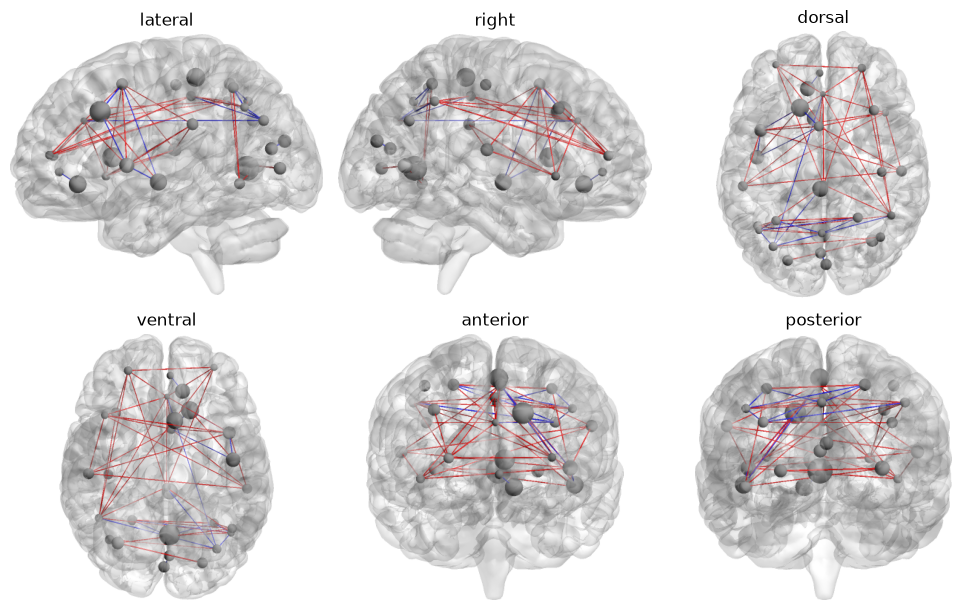

'left' equals 'lateral': True


In [5]:
def trim(img, bg="white"):
    # Crop to the pixels that differ from the background color.
    box = ImageChops.difference(img, Image.new("RGB", img.size, bg)).getbbox()
    return img.crop(box)


views = ["lateral", "right", "dorsal", "ventral", "anterior", "posterior"]
fig, axes = plt.subplots(2, 3, figsize=(10, 6.2))
for ax, view in zip(axes.ravel(), views, strict=False):
    im = htfa.plot_network(
        res, C0, subject=0, threshold=0.5, view=view, size=(700, 440)
    )
    ax.imshow(trim(im))
    ax.set_title(view)
    ax.axis("off")
fig.tight_layout()
plt.show()
print("'left' equals 'lateral':", brainnet.VIEWS["left"] == brainnet.VIEWS["lateral"])

## 4. Edge style and threshold

`threshold` keeps the edges with `|r| > threshold`. `edge_style='intensity'` (default) draws each edge as a tube whose diameter is `|r|` mm at opacity 0.7, so stronger edges are thicker and more opaque; `'flat'` draws every edge as a 0.5 mm opaque tube. `htfa.brainnet.montage` arranges the frames in a labelled grid, with rows labelled by edge style and columns by threshold. The printed counts are the number of edges that remain at each threshold.

threshold 0.7: 7 edges
threshold 0.5: 49 edges
threshold 0.3: 120 edges
(1193, 690)


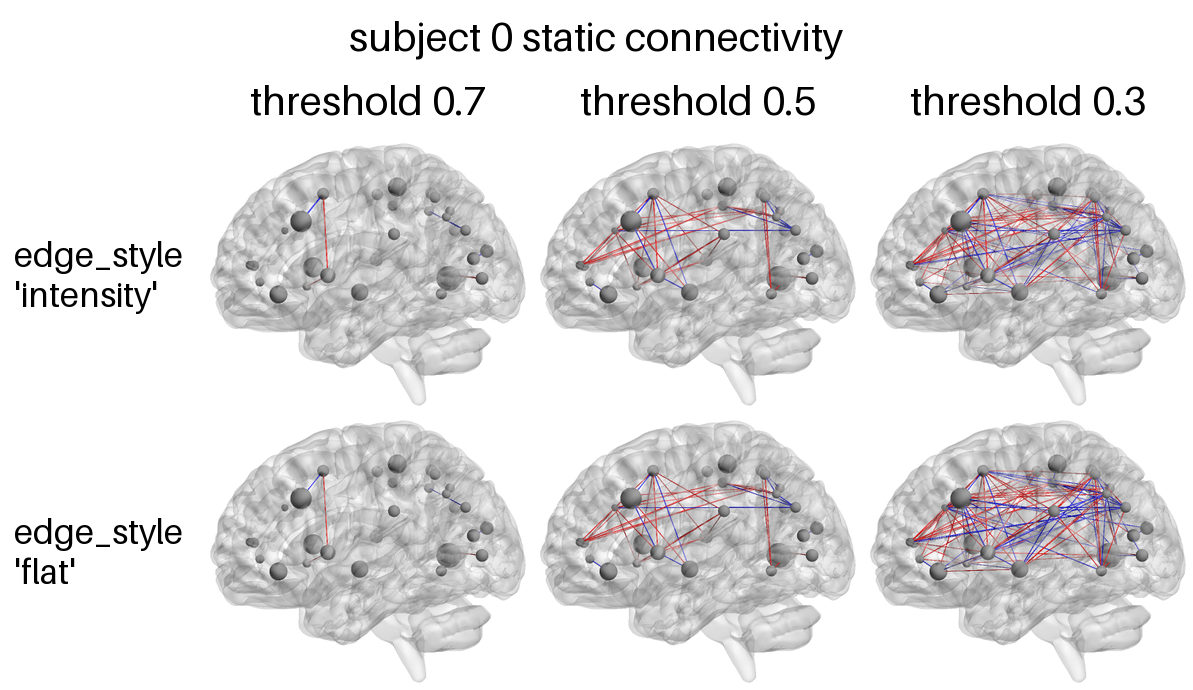

In [6]:
cols = [0.7, 0.5, 0.3]
rows = ["intensity", "flat"]
frames = [
    [
        htfa.plot_network(
            res, C0, subject=0, threshold=th, edge_style=es, size=(700, 440)
        )
        for th in cols
    ]
    for es in rows
]
for th in cols:
    print(f"threshold {th}: {int((a > th).sum())} edges")
m = brainnet.montage(
    frames,
    row_labels=[f"edge_style\n'{r}'" for r in rows],
    col_labels=[f"threshold {c}" for c in cols],
    title="subject 0 static connectivity",
    cell_width=330,
)
print(m.size)
show(m)

## 5. Colors, mesh opacity, background

The style keywords of `plot_network` are `node_color`, `positive_color`, `negative_color`, `mesh_color`, `mesh_opacity` and `background`. Colors can be matplotlib color names or RGB tuples in 0-1. All panels below use `edge_style='flat'` and the same edges.

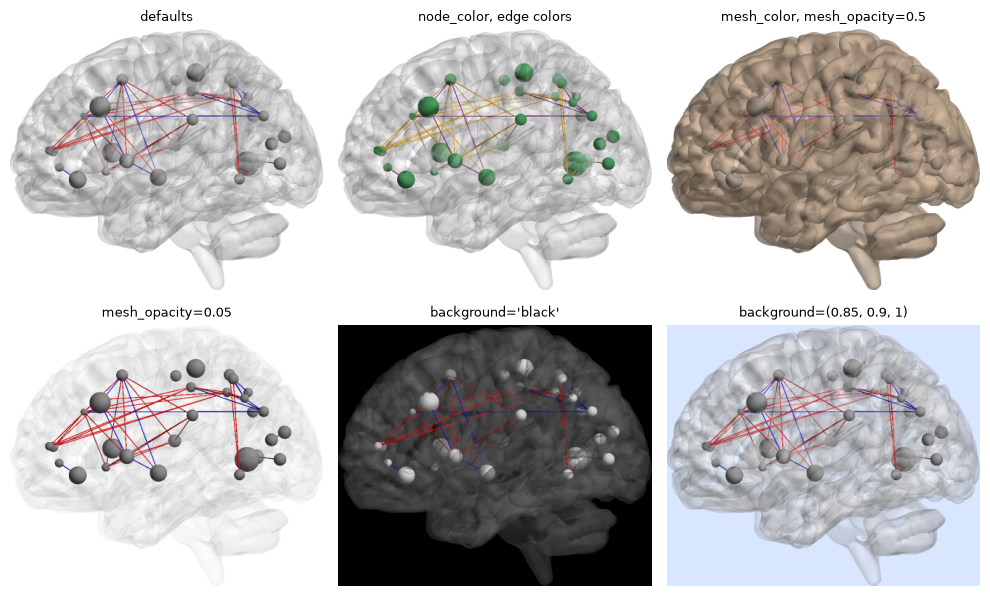

In [7]:
opts = [
    ("defaults", {}),
    (
        "node_color, edge colors",
        dict(
            node_color=(0.1, 0.5, 0.2), positive_color="orange", negative_color="purple"
        ),
    ),
    (
        "mesh_color, mesh_opacity=0.5",
        dict(mesh_color=(0.8, 0.7, 0.6), mesh_opacity=0.5),
    ),
    ("mesh_opacity=0.05", dict(mesh_opacity=0.05)),
    (
        "background='black'",
        dict(
            background="black",
            mesh_color=(0.4, 0.4, 0.4),
            mesh_opacity=0.3,
            node_color="white",
        ),
    ),
    ("background=(0.85, 0.9, 1)", dict(background=(0.85, 0.9, 1.0))),
]
fig, axes = plt.subplots(2, 3, figsize=(10, 6.2))
for ax, (title, kw) in zip(axes.ravel(), opts, strict=False):
    im = htfa.plot_network(
        res, C0, subject=0, threshold=0.5, edge_style="flat", size=(700, 440), **kw
    )
    bg = kw.get("background", "white")
    ax.imshow(
        trim(im, tuple(round(255 * c) for c in bg) if isinstance(bg, tuple) else bg)
    )
    ax.set_title(title, fontsize=9)
    ax.axis("off")
fig.tight_layout()
plt.show()

## 6. Node sizes

With a fit as `nodes`, node sizes default to the factor widths (with the default `snap=True`, the in-brain widths of section 14). The `sizes` argument replaces them with any array of length K. `plot_network` turns the sizes into sphere radii with `htfa.brainnet.node_radius`. By default the smallest size gets a 2 mm radius and the largest 7 mm; equal sizes give 4 mm radii. Three style options change the mapping:

- `radius_range=(lo, hi)`: radii of the smallest and largest size.
- `radius_kb=(k, b)`: a fixed mapping, radius = `k * size + b` mm, so that radii are comparable between plots (BrainNet Viewer stores such values as `nod.k` and `nod.b`).
- `radius_clip=(min, max)`: clips the radii afterwards.

The printed values show what `node_radius` gives for the widths of subject 0 under each choice.

subject 0 widths, min / max: [ 192. 2373.]
default (lo=2, hi=7): [2. 7.]
lo=1, hi=10: [ 1. 10.]
k=0.003, b=0.5: [1.07 7.62]
k=0.003, b=0.5, clip=(2, 5): [2. 5.]
equal sizes: [4.]
in-brain widths drawn by default, min / max: [ 189. 1135.]


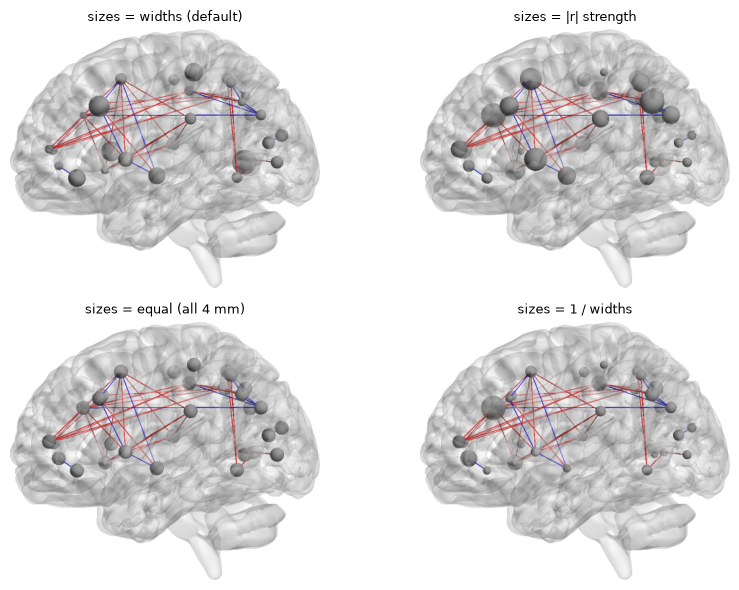

In [8]:
w = res.widths[0]
print("subject 0 widths, min / max:", np.round([w.min(), w.max()]))
k, b = 0.003, 0.5


def span(r):
    return np.round([r.min(), r.max()], 2)


print("default (lo=2, hi=7):", span(brainnet.node_radius(w)))
print("lo=1, hi=10:", span(brainnet.node_radius(w, 1, 10)))
print(f"k={k}, b={b}:", span(brainnet.node_radius(w, k=k, b=b)))
print(
    f"k={k}, b={b}, clip=(2, 5):", span(brainnet.node_radius(w, k=k, b=b, clip=(2, 5)))
)
print("equal sizes:", np.unique(brainnet.node_radius(np.full(5, 3.0))))
_, w_eff, _ = res.display_nodes(0)
print(
    "in-brain widths drawn by default, min / max:", np.round([w_eff.min(), w_eff.max()])
)
strength = np.abs(C0).sum(axis=0)
variants = [
    ("sizes = widths (default)", {}),
    ("sizes = |r| strength", dict(sizes=strength)),
    ("sizes = equal (all 4 mm)", dict(sizes=np.ones(30))),
    ("sizes = 1 / widths", dict(sizes=1.0 / w)),
]
fig, axes = plt.subplots(2, 2, figsize=(9, 6))
for ax, (title, kw) in zip(axes.ravel(), variants, strict=True):
    im = htfa.plot_network(
        res, C0, subject=0, threshold=0.5, edge_style="flat", size=(700, 440), **kw
    )
    ax.imshow(trim(im))
    ax.set_title(title, fontsize=9)
    ax.axis("off")
fig.tight_layout()
plt.show()

The mapping from size to radius for four settings, on sizes from 0 to 1, and `plot_network` with the three style options (default sizes: the in-brain widths).

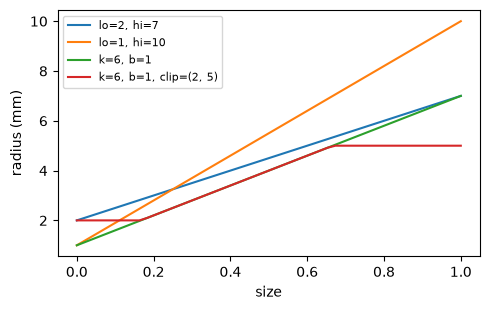

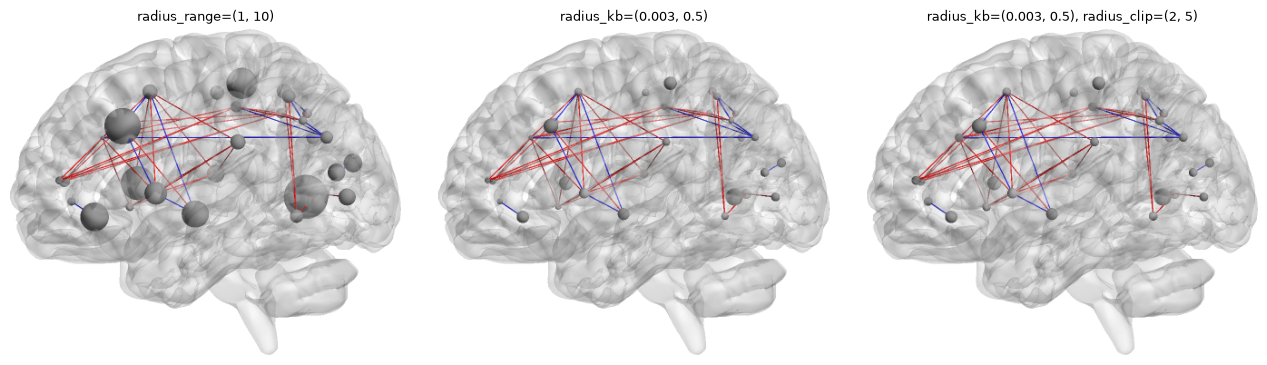

In [9]:
fig, ax = plt.subplots(figsize=(5, 3.2))
x = np.linspace(0, 1, 50)
for kw in [
    dict(lo=2, hi=7),
    dict(lo=1, hi=10),
    dict(k=6, b=1),
    dict(k=6, b=1, clip=(2, 5)),
]:
    ax.plot(
        x,
        brainnet.node_radius(x, **kw),
        label=", ".join(f"{a}={v}" for a, v in kw.items()),
    )
ax.set_xlabel("size")
ax.set_ylabel("radius (mm)")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

opts = [
    ("radius_range=(1, 10)", dict(radius_range=(1, 10))),
    ("radius_kb=(0.003, 0.5)", dict(radius_kb=(0.003, 0.5))),
    (
        "radius_kb=(0.003, 0.5), radius_clip=(2, 5)",
        dict(radius_kb=(0.003, 0.5), radius_clip=(2, 5)),
    ),
]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, (title, kw) in zip(axes, opts, strict=True):
    im = htfa.plot_network(
        res, C0, subject=0, threshold=0.5, edge_style="flat", size=(700, 440), **kw
    )
    ax.imshow(trim(im))
    ax.set_title(title, fontsize=9)
    ax.axis("off")
fig.tight_layout()
plt.show()

## 7. Mesh

`mesh` takes the name of one of the three BrainNet Viewer 1.43 surfaces in `htfa.brainnet.MESHES`, a path to a `.nv` file, a `(vertices, faces)` pair, or `None` for no surface. The vertex and face counts printed below are those of the files in the cache.

mesh names: ['ch2', 'icbm152', 'icbm152_smoothed']


ch2: 77124 vertices, 154244 faces; x range -70 to 72 mm


icbm152: 81924 vertices, 163840 faces; x range -69 to 69 mm


icbm152_smoothed: 81924 vertices, 163840 faces; x range -63 to 63 mm


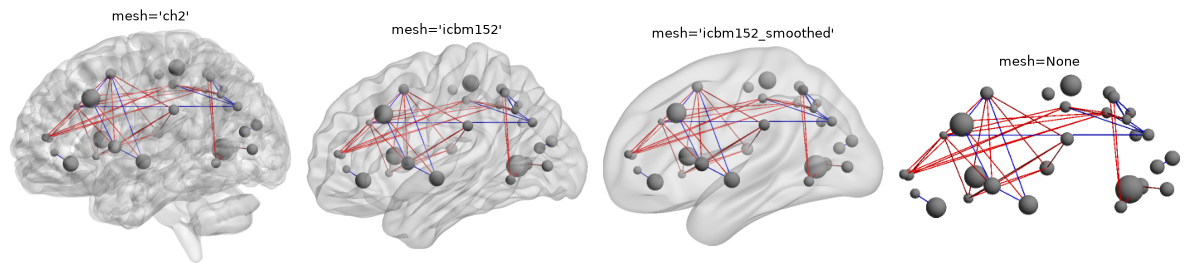

In [10]:
print("mesh names:", sorted(brainnet.MESHES))
meshes = ["ch2", "icbm152", "icbm152_smoothed"]
verts = {}
for name in meshes:
    v, f = brainnet.load_mesh(name)
    verts[name] = (len(v), len(f))
    print(
        f"{name}: {len(v)} vertices, {len(f)} faces; "
        f"x range {v[:, 0].min():.0f} to {v[:, 0].max():.0f} mm"
    )
fig, axes = plt.subplots(1, 4, figsize=(12, 3.2))
for ax, name in zip(axes, [*meshes, None], strict=False):
    im = htfa.plot_network(
        res, C0, subject=0, threshold=0.5, edge_style="flat", mesh=name, size=(700, 440)
    )
    ax.imshow(trim(im))
    ax.set_title(f"mesh={name!r}", fontsize=9)
    ax.axis("off")
fig.tight_layout()
plt.show()

## 8. PNG and JPEG output, image size

`out=` writes the image to a file; the format follows the suffix. A `.jpg` file is written at JPEG quality 75 with 4:2:0 chroma subsampling, which is what MATLAB wrote for the 2014 BrainNet frames; `jpeg_quality=` sets another quality, and also compresses the returned image when no `out` is given. `size=(width, height)` sets the pixel size (default 1600 by 1000). The sizes below are for 1600 by 1000 images; `image_diff` is the mean absolute RGB difference (0 to 255) between two images resized to 400 by 250. The panels show a 150 by 94 pixel patch with thin edges, magnified 4x. At quality 40 the patch shows blocking and color fringes along the edges.

net.png        457 KB   image_diff vs png: 0.0000
net.jpg         94 KB   image_diff vs png: 0.1975
net95.jpg      205 KB   image_diff vs png: 0.1483
net40.jpg       62 KB   image_diff vs png: 0.3795


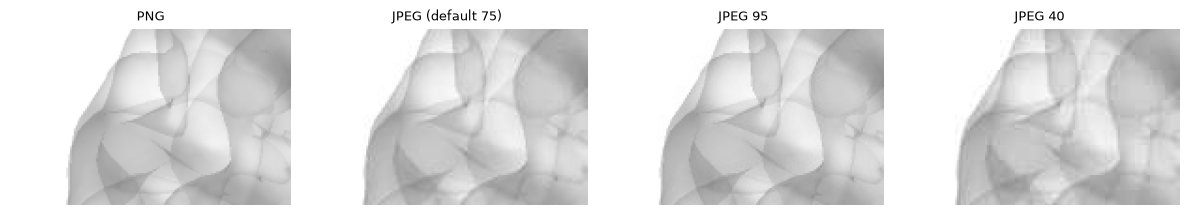

In [11]:
tmp = Path(tempfile.mkdtemp())
big = (1600, 1000)
base = htfa.plot_network(
    res, C0, subject=0, threshold=0.5, size=big, out=tmp / "net.png"
)
htfa.plot_network(res, C0, subject=0, threshold=0.5, size=big, out=tmp / "net.jpg")
htfa.plot_network(
    res, C0, subject=0, threshold=0.5, size=big, out=tmp / "net95.jpg", jpeg_quality=95
)
htfa.plot_network(
    res, C0, subject=0, threshold=0.5, size=big, out=tmp / "net40.jpg", jpeg_quality=40
)
for f in ["net.png", "net.jpg", "net95.jpg", "net40.jpg"]:
    print(
        f"{f:10s} {(tmp / f).stat().st_size / 1024:7.0f} KB   "
        f"image_diff vs png: {brainnet.image_diff(tmp / 'net.png', tmp / f):.4f}"
    )
box = (330, 330, 480, 424)  # a 150 x 94 pixel patch with thin edges, shown at 4x
names = ["net.png", "net.jpg", "net95.jpg", "net40.jpg"]
titles = ["PNG", "JPEG (default 75)", "JPEG 95", "JPEG 40"]
fig, axes = plt.subplots(1, 4, figsize=(12, 2.6))
for ax, f, t in zip(axes, names, titles, strict=False):
    ax.imshow(Image.open(tmp / f).crop(box).resize((600, 376), Image.NEAREST))
    ax.set_title(t, fontsize=9)
    ax.axis("off")
fig.tight_layout()
plt.show()

## 9. BrainNet Viewer option files

`read_brainnet_config` reads a BrainNet Viewer option file (a `.mat` file holding a struct `EC`) and `config_style` turns it into `plot_network` keywords. No option file from BrainNet Viewer is used here: the file below was written with `scipy.io.savemat` in this notebook, with only the fields `config_style` reads (`bak.color`, `msh.color`, `msh.alpha`, `nod.CM`, `edg.CM`, `edg.draw_threshold`). In an `edg.CM` colormap the first row becomes the positive edge color and the last row the negative edge color. The view is always left lateral, whatever the file says. A `.mat` file without `EC` raises `ValueError`.

top-level fields: ['bak', 'edg', 'msh', 'nod']
cfg['edg']['draw_threshold']: 0.5
background      (0.0, 0.0, 0.0)
mesh_color      (0.35, 0.35, 0.4)
mesh_opacity    0.25
node_color      (1.0, 0.8, 0.1)
threshold       0.5
positive_color  (1.0, 0.5, 0.0)
negative_color  (0.0, 0.6, 1.0)
ValueError: <tmp>/bad.mat has no BrainNet option struct 'EC'


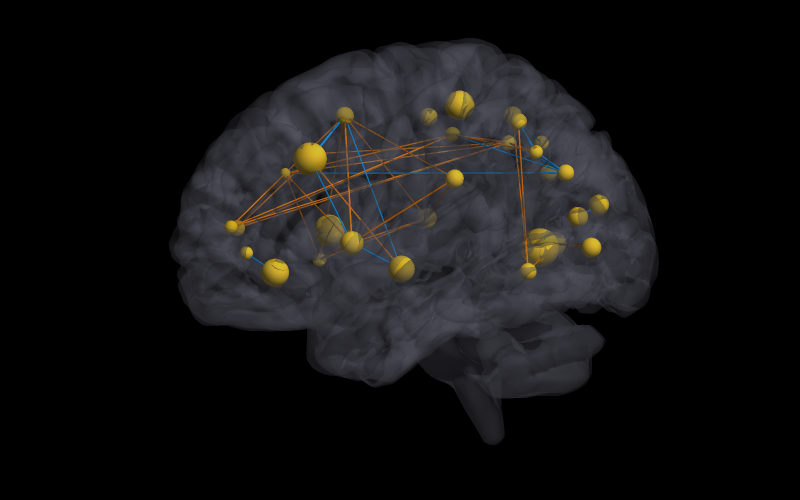

In [12]:
cfg_path = tmp / "dark.mat"
EC = {
    "bak": {"color": np.array([0.0, 0.0, 0.0])},
    "msh": {"color": np.array([0.35, 0.35, 0.4]), "alpha": 0.25},
    "nod": {"CM": np.array([[1.0, 0.8, 0.1]])},
    "edg": {"CM": np.array([[1.0, 0.5, 0.0], [0.0, 0.6, 1.0]]), "draw_threshold": 0.5},
}
scipy.io.savemat(cfg_path, {"EC": EC})
cfg = brainnet.read_brainnet_config(cfg_path)
print("top-level fields:", sorted(cfg))
print("cfg['edg']['draw_threshold']:", cfg["edg"]["draw_threshold"])
style = brainnet.config_style(cfg)
for k, v in style.items():
    print(f"{k:15s} {v}")
try:
    scipy.io.savemat(tmp / "bad.mat", {"x": 1})
    brainnet.read_brainnet_config(tmp / "bad.mat")
except ValueError as e:
    print("ValueError:", str(e).replace(str(tmp), "<tmp>"))
img = htfa.plot_network(res, C0, subject=0, size=(800, 500), **style)
show(img)

## 10. Side-by-side panels

`annotate_pair` places two frames side by side under a header band with a title (and optional subtitle after `\n`) for each, and an optional caption. By default each frame is cropped to the box around the non-white pixels of both. `crop=(left, top, right, bottom)` selects the region of each frame instead; the second call below crops to the front half of the dorsal frames.

(900, 669)


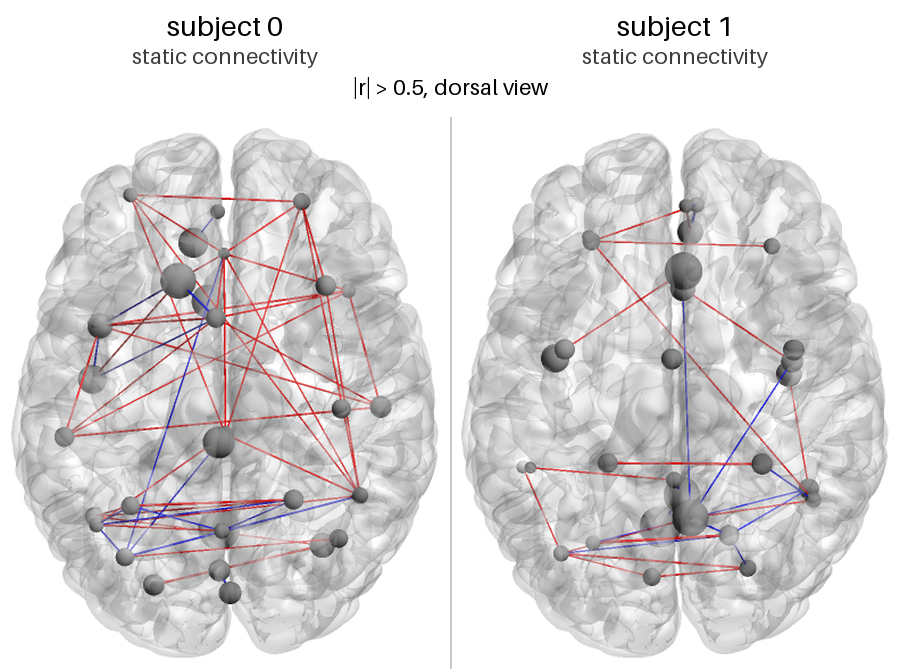

In [13]:
C1 = res.connectivity(1)
np.fill_diagonal(C1, 0)
p = [
    htfa.plot_network(res, C, subject=s, threshold=0.5, view="dorsal", size=(800, 500))
    for s, C in [(0, C0), (1, C1)]
]
pair = brainnet.annotate_pair(
    p[0],
    p[1],
    ("subject 0\nstatic connectivity", "subject 1\nstatic connectivity"),
    caption="|r| > 0.5, dorsal view",
    width=900,
)
print(pair.size)
show(pair)

Cropped version of the same pair:

with crop=(180, 20, 620, 300): (900, 339)  default crop: (900, 669)


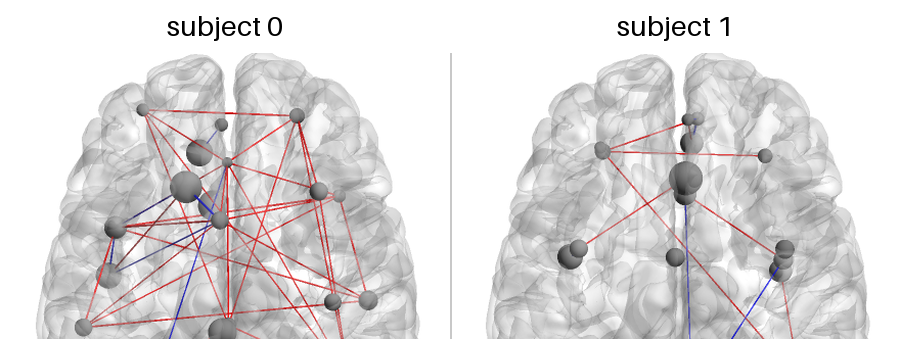

In [14]:
pair2 = brainnet.annotate_pair(
    p[0], p[1], ("subject 0", "subject 1"), width=900, crop=(180, 20, 620, 300)
)
print("with crop=(180, 20, 620, 300):", pair2.size, " default crop:", pair.size)
show(pair2)

## 11. Time courses

`htfa.plot_timecourse` draws each condition as a mean line with a +/- SEM ribbon over subjects (rows of a `(subjects, time)` array); a 1D array is drawn as a single line. **The curves in this section's first three figures are synthetic**: 12 subjects, 160 samples every 2 s, a random walk plus noise with a Gaussian bump centered at 220 s (amplitude 0.5 for `remember` and 1.2 for `forget`).

shape per condition: (12, 160)


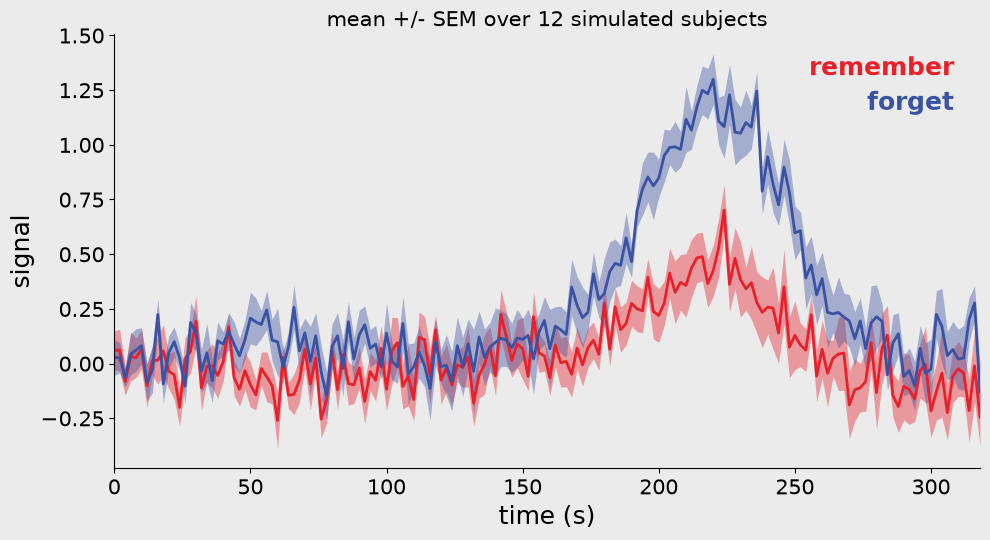

In [15]:
rng = np.random.default_rng(0)
S, T = 12, 160
t = np.arange(T) * 2.0  # seconds


def make(effect, rng):
    base = np.cumsum(rng.standard_normal((S, T)), axis=1) * 0.03
    bump = effect * np.exp(-0.5 * ((t - 220) / 25) ** 2)
    return base + bump + 0.3 * rng.standard_normal((S, T))


conds = {"remember": make(0.5, rng), "forget": make(1.2, rng)}
print("shape per condition:", conds["remember"].shape)
fig = htfa.plot_timecourse(
    conds,
    t,
    xlabel="time (s)",
    ylabel="signal",
    title="mean +/- SEM over 12 simulated subjects",
)
plt.show()

`smooth=n` (odd `n`) applies a centered moving average of `n` samples to each subject before the mean and SEM are computed. The first and last samples are left unchanged, which is visible as a step at the right edge of the smoothed curves.

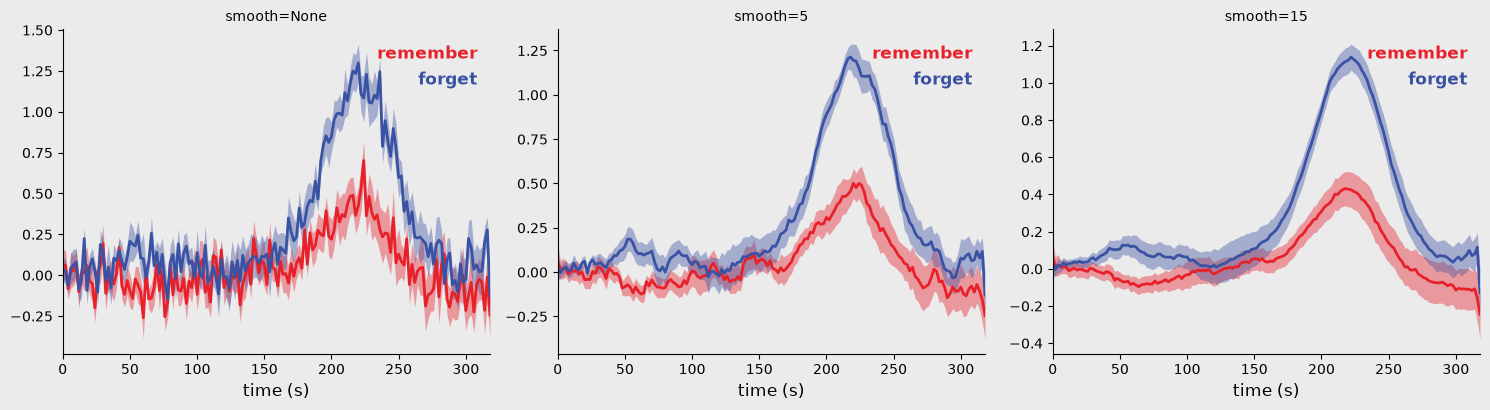

moving_average(range(7), 3): [0. 1. 2. 3. 4. 5. 6.]


In [16]:
fig, axes = plt.subplots(
    1, 3, figsize=(15, 4.2), facecolor=timecourse.SLIDE_COLORS["background"]
)
for ax, sm in zip(axes, [None, 5, 15], strict=False):
    htfa.plot_timecourse(
        conds, t, smooth=sm, ax=ax, fontsize=12, title=f"smooth={sm}", xlabel="time (s)"
    )
plt.show()
print("moving_average(range(7), 3):", timecourse.moving_average(np.arange(7.0), 3))

`shared_before=x` draws the mean of all conditions as one dark curve before `x`, and the condition curves start one sample earlier. `events` adds vertical magenta lines, `periods` shades x ranges, `colors` overrides the default slide red and blue, and `fontsize`, `title`, `xlabel` and `ylabel` set the text. The default colors and the background are in `htfa.timecourse.SLIDE_COLORS`.

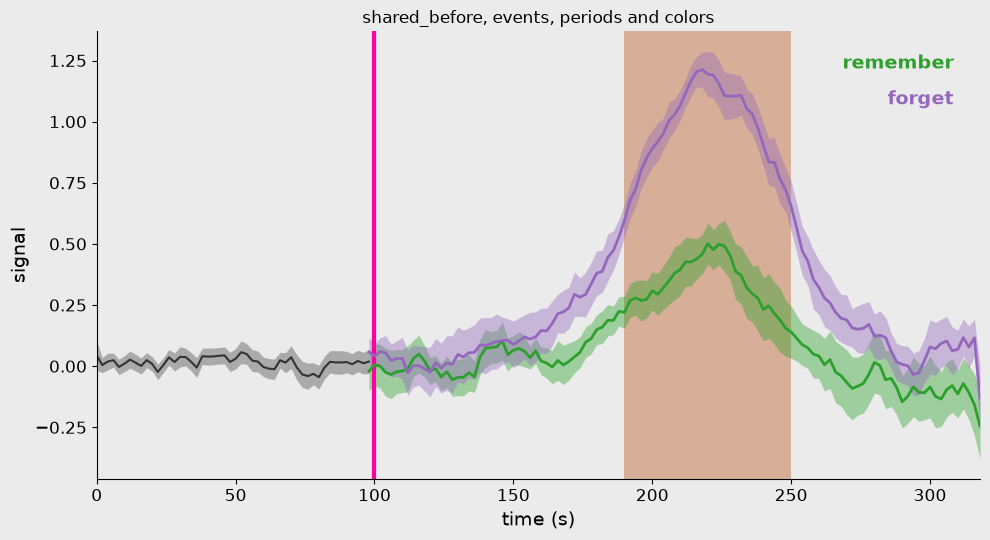

SLIDE_COLORS: {'red': '#E8202A', 'blue': '#3A52A4', 'dark': '#333333', 'event': '#FF00A0', 'period': '#D2A184', 'background': '#EBEBEB'}


In [17]:
fig = htfa.plot_timecourse(
    conds,
    t,
    smooth=5,
    shared_before=100,
    events=[100.0],
    periods=[(190, 250)],
    colors={"remember": "tab:green", "forget": "tab:purple"},
    xlabel="time (s)",
    ylabel="signal",
    title="shared_before, events, periods and colors",
    fontsize=14,
)
plt.show()
print("SLIDE_COLORS:", timecourse.SLIDE_COLORS)

**Real data.** `res.dynamic_connectivity(subject, window=20)` gives one correlation matrix per 20-sample window. `timecourse.global_connectivity` (mean of the upper triangle including the diagonal) and `timecourse.edge_count` (number of edges above a threshold) turn each subject's sequence of matrices into one curve; the ribbons are mean +/- SEM over the six subjects. Here the x axis is the start of each window in seconds (2 s per sample). The two quantities are drawn in separate axes.

dynamic connectivity per subject: (6, 149, 30, 30)
global connectivity per window, mean over subjects, min / max: [0.077 0.102]


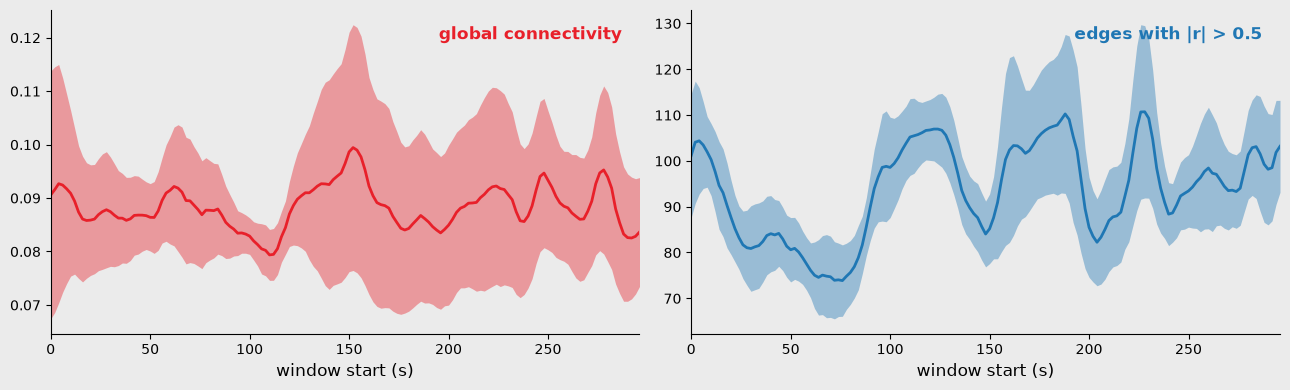

In [18]:
frames = np.stack([res.dynamic_connectivity(s, window=20) for s in range(6)])
print("dynamic connectivity per subject:", frames.shape)
gc = np.stack([timecourse.global_connectivity(f) for f in frames])
ec = np.stack([timecourse.edge_count(f, threshold=0.5) for f in frames])
print(
    "global connectivity per window, mean over subjects, min / max:",
    np.round([gc.mean(0).min(), gc.mean(0).max()], 3),
)
fig, axes = plt.subplots(
    1, 2, figsize=(13, 4), facecolor=timecourse.SLIDE_COLORS["background"]
)
x = np.arange(gc.shape[1]) * 2.0
htfa.plot_timecourse(
    {"global connectivity": gc},
    x,
    smooth=5,
    ax=axes[0],
    fontsize=12,
    xlabel="window start (s)",
)
htfa.plot_timecourse(
    {"edges with |r| > 0.5": ec},
    x,
    smooth=5,
    ax=axes[1],
    fontsize=12,
    xlabel="window start (s)",
    colors={"edges with |r| > 0.5": "tab:blue"},
)
plt.show()

## 12. matplotlib and nilearn plots on `HTFAResults`

These three methods need the `plot` extra. With 3D coordinates `plot_nodes` and `plot_connectivity` return nilearn glass-brain displays; with 2D coordinates they return matplotlib figures. The next two figures use the real fit.

`plot_nodes()` with the default `subject='global'` draws the HTFA template centers in black (by default at their in-brain positions, see section 14) and every subject's centers in a different color (a Spectral colormap).

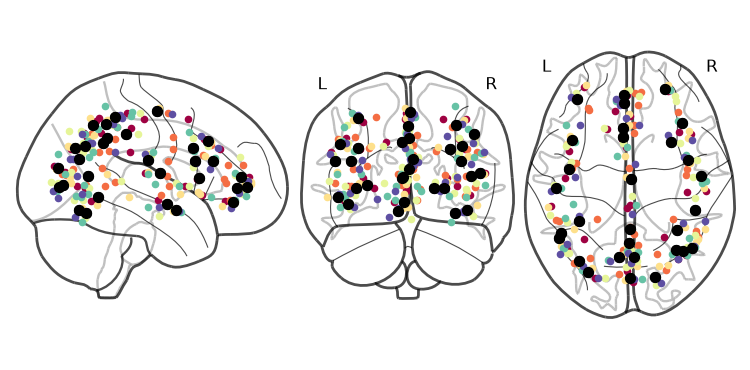

In [19]:
fig = res.plot_nodes()
plt.show()

`subject=0` draws that subject's centers only; extra keyword arguments go to `nilearn.plotting.plot_connectome` (here `display_mode` and `title`).

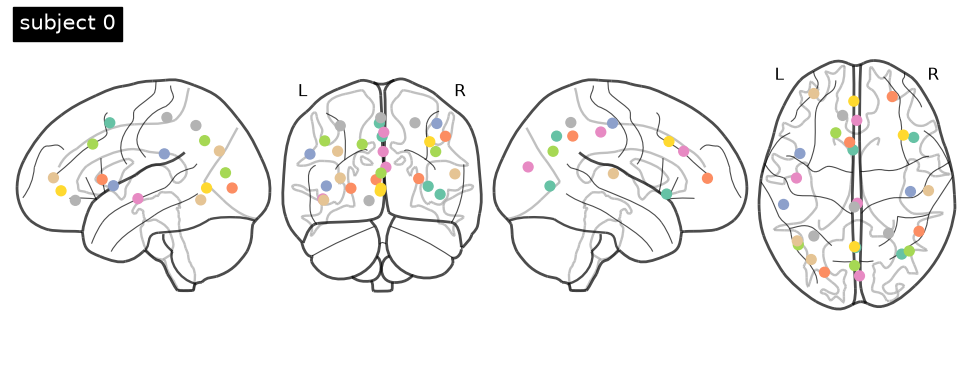

In [20]:
disp = res.plot_nodes(subject=0, display_mode="lyrz", title="subject 0")
plt.show()

`plot_connectivity` draws the subject's edges between factor centers with nilearn's `plot_connectome`. `threshold` is a percentage string (`'95%'` keeps the edges at or above the 95th percentile of |r|) or an absolute value. In the colorbar, the gray band spans the values below the threshold.

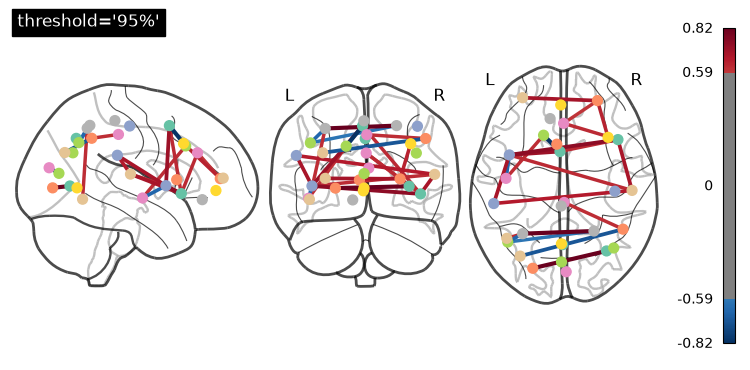

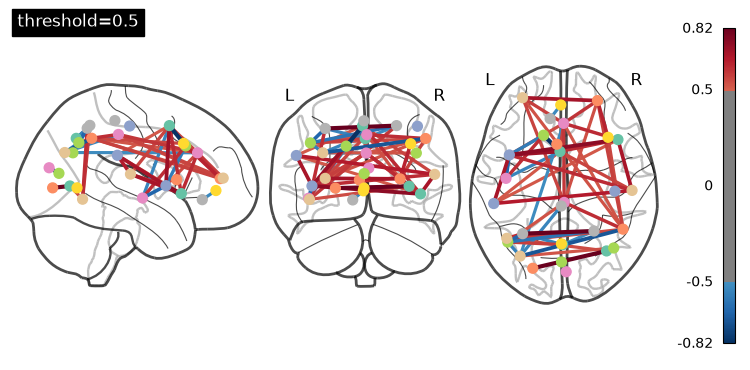

In [21]:
for th in ["95%", 0.5]:
    disp = res.plot_connectivity(subject=0, threshold=th)
    disp.title(f"threshold={th!r}", size=12)
    plt.show()

## 13. 2D data: `plot_nodes`, `plot_connectivity`, `plot_reconstruction`

On 2D data the same methods draw matplotlib figures, so `ax=` places them in your own layout. The data here are **synthetic**: a 24 by 24 image grid, 60 samples, 6 factors (`htfa.make_tfa_data`), fitted with `htfa.fit`. `plot_connectivity` accepts a percentage string (the percentile of the absolute correlations) or an absolute threshold. `plot_reconstruction` shows one sample of the standardized data next to the reconstruction.

For 3D data, `plot_reconstruction` needs NIfTI input (an affine); the fit above was made from arrays and coordinates, so it raises `ValueError`. The printed correlations show that no edge of this fit has `|r|` above 0.5, so the third panel of the connectivity figure has nodes but no edges.

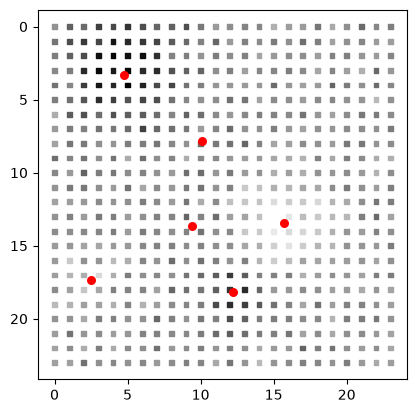

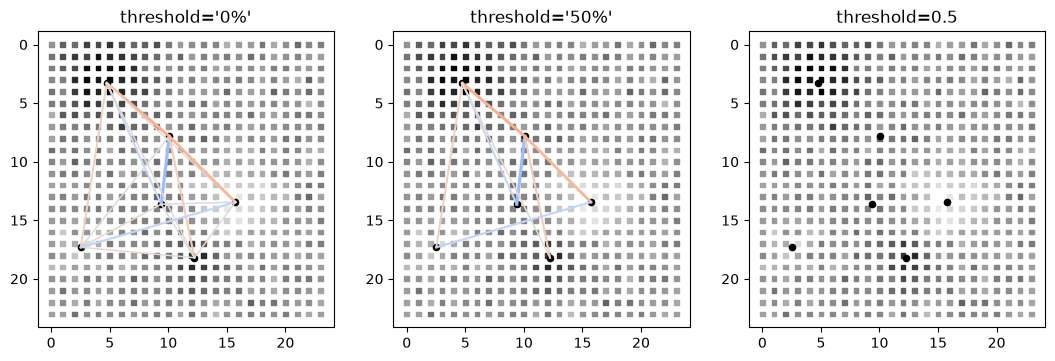

2D fit, |r| values off the diagonal (upper triangle): [0.03 0.03 0.04 0.04 0.04 0.05 0.05 0.05 0.14 0.15 0.18 0.18 0.34 0.38
 0.42]


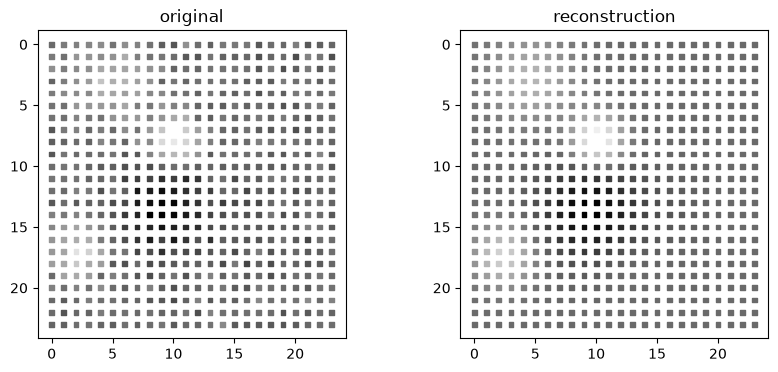

ValueError: 3D plot_reconstruction needs NIfTI input (affine)


In [22]:
X2, R2, _ = htfa.make_tfa_data((24, 24), 60, K=6, noise=0.2, random_state=0)
res2 = htfa.fit(
    X2, K=6, coords=R2, standardize=False, init="ncorr", max_iter=30, random_state=0
)
fig = res2.plot_nodes()
plt.show()
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, th in zip(axes, ["0%", "50%", 0.5], strict=False):
    res2.plot_connectivity(threshold=th, ax=ax)
    ax.set_title(f"threshold={th!r}")
plt.show()
C2 = res2.connectivity()
np.fill_diagonal(C2, 0)
print(
    "2D fit, |r| values off the diagonal (upper triangle):",
    np.round(np.sort(np.abs(C2[np.triu_indices(6, 1)])), 2),
)
fig = res2.plot_reconstruction(sample=5)
plt.show()
try:
    res.plot_reconstruction(subject=0)
except ValueError as e:
    print("ValueError:", e)
plt.close("all")  # the failed call left an empty two-panel figure open

## 14. Node positions inside the brain (snapping)

A fitted center is not constrained to lie inside the brain: a Gaussian RBF centered just outside the cortex still reaches into it, and that is how a fit can explain a blurry cortical activation. The fit therefore keeps its centers as they are. For plotting only, every node is drawn as the part of its RBF that lies inside the brain: its position is the RBF-weighted centroid of the in-brain voxels, and its size comes from the weighted spread (`lambda_eff = 2 * sigma_eff**2`). A node well inside the brain keeps its center and width. This is on by default in all built-in node plots (`plot_network`, `animate_network`, `plot_nodes`, `plot_connectivity`). `snap=False` draws the fitted centers and widths instead, and `mask=` replaces the in-brain voxels (default: the subject's own voxels, or all subjects' voxels for the template).

The left panel below uses `snap=False` and the right panel the default, for the same subject and edges.

image_diff, snap=False vs default: 5.32


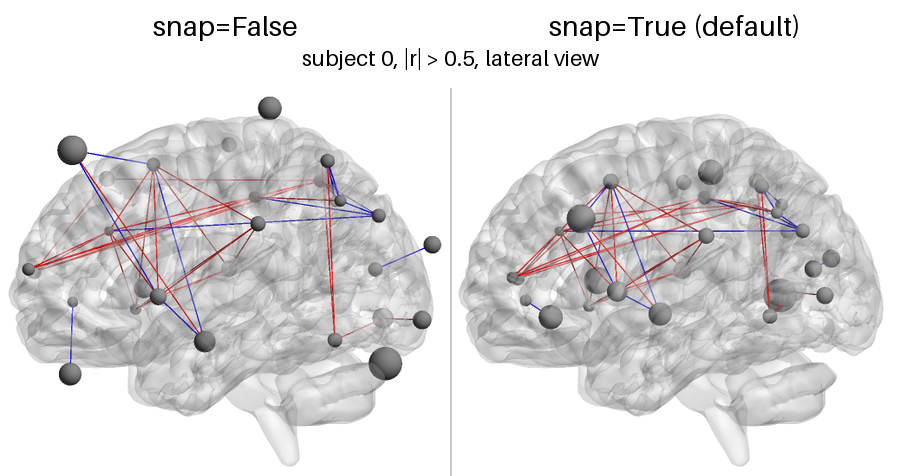

In [23]:
kw = dict(subject=0, threshold=0.5, edge_style="flat", size=(800, 500))
img_off = htfa.plot_network(res, C0, snap=False, **kw)
img_on = htfa.plot_network(res, C0, **kw)
print(
    "image_diff, snap=False vs default:", round(brainnet.image_diff(img_off, img_on), 2)
)
pair = brainnet.annotate_pair(
    img_off,
    img_on,
    ("snap=False", "snap=True (default)"),
    caption="subject 0, |r| > 0.5, lateral view",
    width=900,
)
show(pair)

`res.display_nodes(subject)` returns the centers and widths that a plot with the default `snap=True` draws, plus an info dictionary. The table lists, for the nodes of subject 0 that moved the most: how far the node moved (`distance`), whether the centroid had to be pulled back into the mask (`snapped`, for a concave mask), whether nearest voxels were tied (`ambiguous`), the fraction of the RBF mass that is inside the brain (`mass_fraction`), and `lambda_eff / lambda`. The counts are printed for subject 0 and for the template.

In [24]:
pd = htfa.require("pandas", extra="nilearn")

before = res.centers[0].copy()
centers_eff, widths_eff, info = res.display_nodes(0)
table = pd.DataFrame(
    {
        "distance (mm)": info["distance"],
        "snapped": info["snapped"],
        "ambiguous": info["ambiguous"],
        "mass_fraction": info["mass_fraction"],
        "lambda": res.widths[0],
        "lambda_eff": widths_eff,
        "lambda_eff/lambda": info["width_ratio"],
    }
).round(2)
print(
    "subject 0: nodes moved by more than 5 mm:",
    int((info["distance"] > 5).sum()),
    "of",
    len(table),
)
print("subject 0: nodes moved by more than 10 mm:", int((info["distance"] > 10).sum()))
_, _, ginfo = res.display_nodes("global")
print(
    "template: moved by more than 5 mm:",
    int((ginfo["distance"] > 5).sum()),
    " more than 10 mm:",
    int((ginfo["distance"] > 10).sum()),
)
print(
    "subject 0: snapped:",
    int(info["snapped"].sum()),
    " ambiguous:",
    int(info["ambiguous"].sum()),
)
print(
    "fitted centers unchanged by display_nodes:", np.array_equal(res.centers[0], before)
)
table.sort_values("distance (mm)", ascending=False).head(8)

subject 0: nodes moved by more than 5 mm: 24 of 30
subject 0: nodes moved by more than 10 mm: 22


template: moved by more than 5 mm: 25  more than 10 mm: 25
subject 0: snapped: 0  ambiguous: 0
fitted centers unchanged by display_nodes: True


,distance (mm),snapped,ambiguous,mass_fraction,lambda,lambda_eff,lambda_eff/lambda
15,39.98,False,False,0.21,2028.87,950.04,0.47
21,36.61,False,False,0.26,2373.27,1134.59,0.48
28,27.22,False,False,0.29,1390.91,765.38,0.55
27,27.04,False,False,0.35,1469.56,824.58,0.56
0,25.19,False,False,0.29,1242.34,610.46,0.49
20,24.95,False,False,0.24,797.91,464.07,0.58
7,23.47,False,False,0.27,1019.07,491.25,0.48
14,22.11,False,False,0.32,930.07,531.06,0.57


`htfa.brainnet.effective_nodes(centers, widths, mask)` does the same computation for any centers. For a bare array of MNI centers, `htfa.brainnet.mni_mask()` gives the 2 mm MNI152 brain mask that `plot_network` uses by default for such input (it ships with nilearn). Below, the template centers of the fit are used as bare arrays: once with their widths, and once without widths, in which case each node is a point that stays if it is inside the mask and otherwise moves to the nearest mask voxel.

In [25]:
mask = brainnet.mni_mask()
print(
    "mni_mask:",
    mask.shape,
    "voxel centers, x range",
    mask[:, 0].min(),
    "to",
    mask[:, 0].max(),
    "mm",
)
c_eff, w_eff_g, info_g = brainnet.effective_nodes(
    res.global_centers, res.global_widths, mask
)
c_pt, _, info_pt = brainnet.effective_nodes(res.global_centers, None, mask)
print(
    "with widths: moved > 5 mm:",
    int((info_g["distance"] > 5).sum()),
    " > 10 mm:",
    int((info_g["distance"] > 10).sum()),
)
print(
    "as points:   moved > 0 mm:",
    int((info_pt["distance"] > 0).sum()),
    " > 10 mm:",
    int((info_pt["distance"] > 10).sum()),
)
print("info keys:", sorted(info_g))
print(
    "mass_fraction of the template nodes, min / median / max:",
    np.round(
        [
            info_g["mass_fraction"].min(),
            np.median(info_g["mass_fraction"]),
            info_g["mass_fraction"].max(),
        ],
        2,
    ),
)

mni_mask: (235375, 3) voxel centers, x range -72.0 to 72.0 mm


with widths: moved > 5 mm: 25  > 10 mm: 25
as points:   moved > 0 mm: 2  > 10 mm: 0
info keys: ['ambiguous', 'distance', 'mass_fraction', 'sigma', 'snapped', 'width_ratio']
mass_fraction of the template nodes, min / median / max: [0.26 0.52 0.98]


Nodes that lie mostly outside the brain have a small `mass_fraction`. `fade_by_mass=True` draws a node with opacity `0.15 + 0.85 * mass_fraction` (a float sets the floor instead of 0.15), and `scale_by_mass=True` multiplies the node sizes by `mass_fraction` before they are mapped to radii. Both need `snap=True`. Panels, left to right: default, `fade_by_mass=True`, `scale_by_mass=True`; the template nodes are drawn with the template's ISFC edges.

template mass_fraction, min / max: [0.26 0.98]


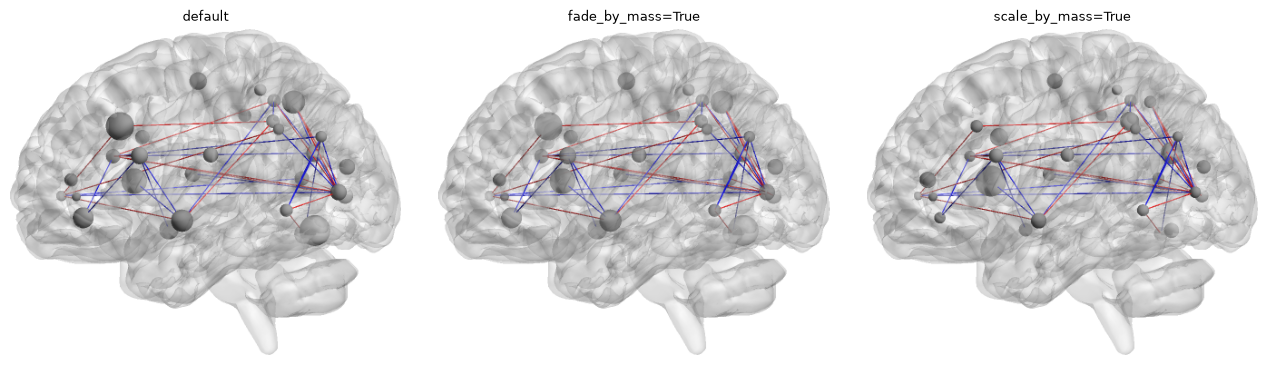

In [26]:
Cg = res.isfc()
np.fill_diagonal(Cg, 0)
mass = res.display_nodes("global")[2]["mass_fraction"]
print("template mass_fraction, min / max:", np.round([mass.min(), mass.max()], 2))
variants = [
    ("default", {}),
    ("fade_by_mass=True", dict(fade_by_mass=True)),
    ("scale_by_mass=True", dict(scale_by_mass=True)),
]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, (title, extra) in zip(axes, variants, strict=True):
    im = htfa.plot_network(
        res, Cg, threshold=0.1, edge_style="flat", size=(700, 440), **extra
    )
    ax.imshow(trim(im))
    ax.set_title(title, fontsize=9)
    ax.axis("off")
fig.tight_layout()
plt.show()

The glass-brain `plot_nodes` follows the same rule. The first figure is the default (in-brain positions), the second `snap=False` (the fitted centers).

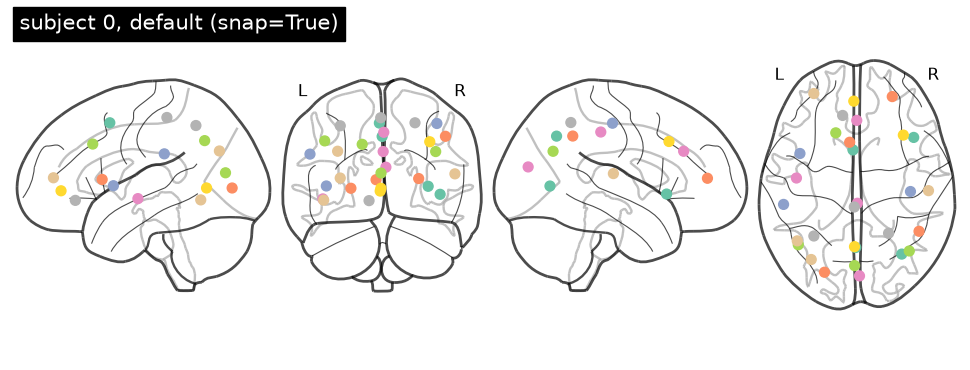

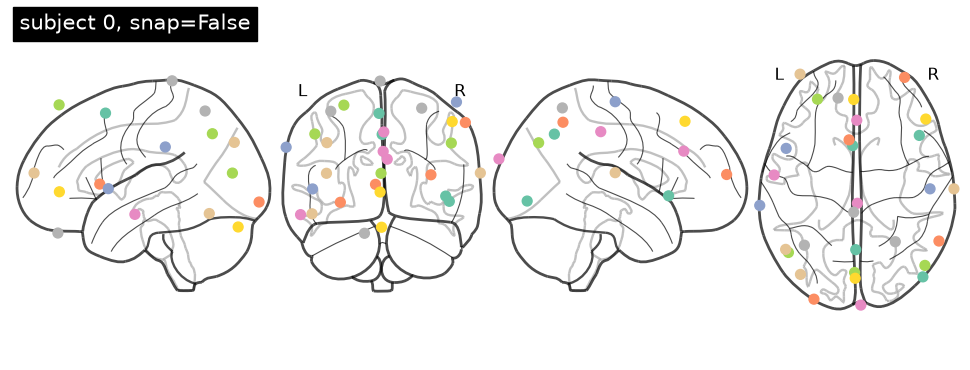

In [27]:
res.plot_nodes(subject=0, display_mode="lyrz", title="subject 0, default (snap=True)")
plt.show()
res.plot_nodes(
    subject=0, display_mode="lyrz", snap=False, title="subject 0, snap=False"
)
plt.show()

## 15. Animation options

`htfa.animate_network` and `res.animate_network` write an mp4 or a looping GIF. By default the movie has one frame per connectivity window and a fixed camera, and `fps` (default 10) sets the frame rate. Three more options change this:

- `duration=` (seconds) gives the movie `round(duration * fps)` frames, whatever the number of windows `T`. Movie frame `i` of `n` shows the window time `t = i * (T - 1) / (n - 1)`, so the windows play in slow motion (`n > T`) or fast forward (`n < T`). `n_frames=` sets the number of frames directly.
- `interpolation=` sets what a frame between two windows shows: `'linear'` (default) draws the weighted mix of the two matrices, so an edge fades in or out as its weight crosses `threshold`, and `'nearest'` draws the nearest window.
- `spin=(x, y, z)` turns the brain `x`, `y` and `z` full turns about the MNI x, y and z axes over the whole movie, in that order, about the center of the mesh's bounding box. Fractions such as 0.5 are allowed. The camera orbits the brain together with its light and keeps the parallel projection. Its zoom is the largest that keeps the whole brain inside every frame, so a spinning brain is drawn smaller than with a fixed `view`. Frame `k` of `n` is turned by `k / n` of `spin`, so a whole number of turns loops without a repeated frame.

A single `(K, K)` matrix with `duration` (or `n_frames`) gives a movie of fixed edges, for a spin. `captions=` takes one string per window (a frame between windows takes the caption of the nearest one) or a function of the window time `t`.

The GIF below spins the template network of section 14 (template ISFC, `|r| > 0.1`, flat edges) once about the vertical (z) axis: 3 s at 10 frames per second, 400 x 250 pixels. Each frame is 1/30 of a turn further than the one before it.

In [28]:
# Figures embedded in the documentation (./figures outside the docs).
DOCS = Path.cwd().parent / "_static"
STATIC = DOCS / "tutorials" if DOCS.is_dir() else Path("figures")
STATIC.mkdir(parents=True, exist_ok=True)
t0 = time.perf_counter()
gif = res.animate_network(
    STATIC / "11_spin.gif",
    connectivity=Cg,
    fps=10,
    duration=3,
    spin=(0, 0, 1),
    threshold=0.1,
    edge_style="flat",
    size=(400, 250),
)
with Image.open(gif) as g:
    n_gif = g.n_frames
print(
    f"{gif.name}: {n_gif} frames, {gif.stat().st_size / 1e6:.2f} MB, "
    f"{time.perf_counter() - t0:.1f} s to render"
)

11_spin.gif: 30 frames, 1.33 MB, 2.0 s to render


![Template network turning once about the z axis](https://raw.githubusercontent.com/ContextLab/htfa/main/docs/_static/tutorials/11_spin.gif)

**Interpolation.** Three windows of subject 0's sliding-window connectivity (`window=20`; windows 0, 60 and 120), drawn as 5 frames with `n_frames=5`, so the frames are at `t = 0, 0.5, 1, 1.5, 2`. With `'linear'` the frames at `t = 0.5` and `1.5` show the mean of two windows: only the edges with `|r| > 0.5` in that mean are drawn. With `'nearest'` they repeat the following window (halves round up). Dorsal view, flat edges.

edges per window (0, 60, 120): [110, 118, 82]
edges per 'linear' frame: [110, 53, 118, 70, 82]


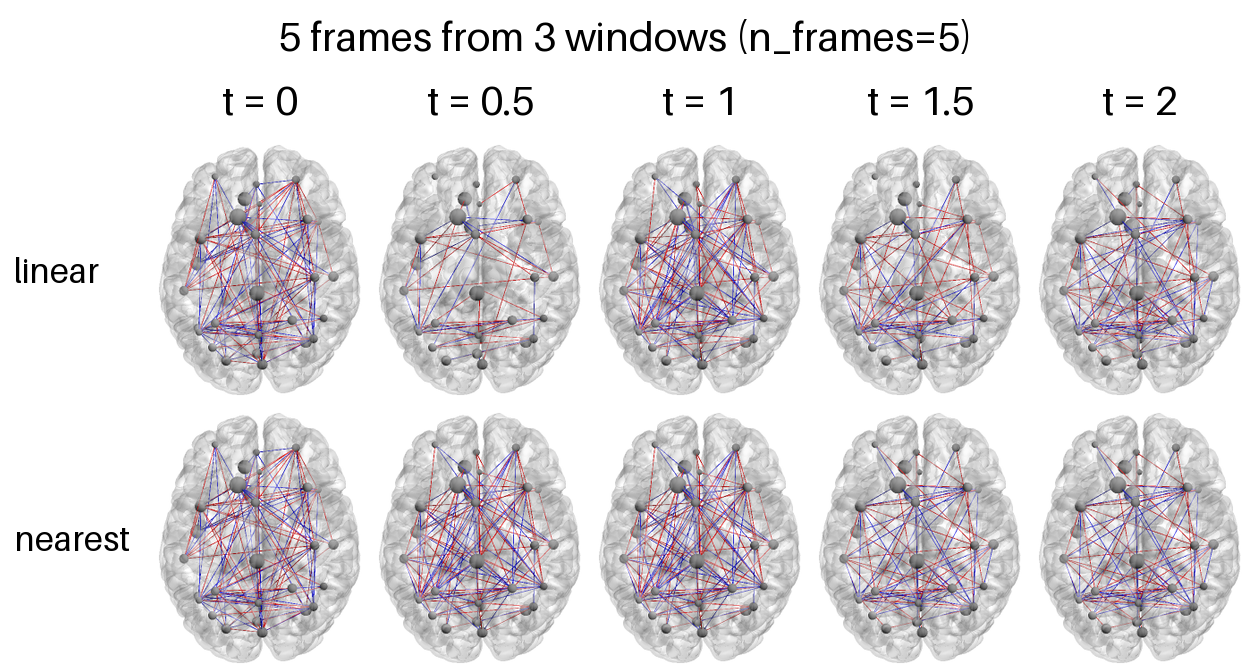

In [29]:
D = res.dynamic_connectivity(0, window=20)
picks = [0, 60, 120]
times = np.linspace(0, len(picks) - 1, 5)
kw = dict(subject=0, threshold=0.5, edge_style="flat", view="dorsal", size=(480, 300))
rows = []
for mode in ["linear", "nearest"]:
    folder = tmp / f"interp_{mode}"
    res.animate_network(
        tmp / f"{mode}.gif",
        connectivity=D[picks],
        n_frames=5,
        interpolation=mode,
        frames_dir=folder,
        **kw,
    )
    rows.append([folder / f"{k}.png" for k in range(1, 6)])


def n_edges(E, th=0.5):
    return int((np.abs(E[np.triu_indices(len(E), 1)]) > th).sum())


a, b, c = D[picks]
print("edges per window (0, 60, 120):", [n_edges(E) for E in (a, b, c)])
print(
    "edges per 'linear' frame:",
    [n_edges(E) for E in (a, (a + b) / 2, b, (b + c) / 2, c)],
)
grid = brainnet.montage(
    rows,
    ["linear", "nearest"],
    [f"t = {t:g}" for t in times],
    title="5 frames from 3 windows (n_frames=5)",
    cell_width=220,
)
show(grid)

**Duration, frame rate and caption functions.** Ten windows played over 4 s at 12 frames per second give 48 frames, about five per window. The caption function receives the window time of each frame. The mp4 is written to a temporary folder; the middle frame is shown.

10 windows -> 48 frames at 12 fps = 4 s


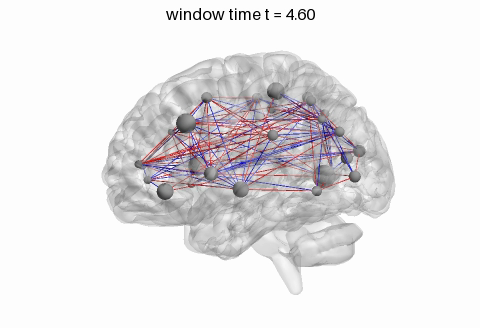

In [30]:
iio = htfa.require("imageio.v2")

mp4 = res.animate_network(
    tmp / "slow.mp4",
    subject=0,
    connectivity=D[:10],
    fps=12,
    duration=4,
    captions=lambda t: f"window time t = {t:.2f}",
    threshold=0.5,
    edge_style="flat",
    size=(480, 300),
)
reader = iio.get_reader(mp4, "ffmpeg")
try:
    n = reader.count_frames()
    fps = reader.get_meta_data()["fps"]
    middle = Image.fromarray(reader.get_data(n // 2))
finally:
    reader.close()
print(f"10 windows -> {n} frames at {fps:g} fps = {n / fps:g} s")
show(middle)

## Notes

- `plot_network` needs the `brain3d` extra and the NITRC meshes; the time-course and `HTFAResults` plots need only `plot`. htfa installs the extras and downloads the meshes the first time they are needed.
- Rendering is off-screen with pyvista.